In [4]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & DEPENDENCIES
# AI-Based Fake Job Advertisement Detection & Verification System
# ==============================================================================

print(">> [1/7] Installing Tesseract OCR system packages and Python libraries...")

# Install Tesseract OCR binary cleanly (suppressing package mirror warnings)
!apt-get update -qq --fix-missing > /dev/null 2>&1 || true
!apt-get install -y -qq tesseract-ocr libtesseract-dev fonts-dejavu-core > /dev/null 2>&1

# Install compatible Python libraries quietly
!pip install -q \
    tensorflow>=2.15.0 \
    gradio>=4.20.0 \
    pytesseract>=0.3.10 \
    opencv-python>=4.8.0 \
    pillow>=10.0.0 \
    matplotlib>=3.7.0 \
    seaborn>=0.12.0 \
    scikit-learn>=1.3.0

import os
import re
import sys
import glob
import math
import random
import shutil
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import cv2
import pytesseract

# Configure Tesseract path (standard in Colab Linux)
# Configure Tesseract path (cross-platform: Colab, Linux, Windows, macOS)
if os.path.exists('/usr/bin/tesseract'):
    pytesseract.pytesseract.tesseract_cmd = '/usr/bin/tesseract'
elif shutil.which('tesseract'):
    pytesseract.pytesseract.tesseract_cmd = shutil.which('tesseract')
elif os.path.exists(r'C:\Program Files\Tesseract-OCR\tesseract.exe'):
    pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
elif os.path.exists(r'C:\Program Files (x86)\Tesseract-OCR\tesseract.exe'):
    pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files (x86)\Tesseract-OCR\tesseract.exe'

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# Verify GPU or CPU availability
print(f"TensorFlow Version: {tf.__version__}")
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"CUDA GPU Detected: {gpu_devices[0].name} (Accelerated mode)")
else:
    print("Running on CPU (Optimized lightweight CNN: trains in ~10 seconds on CPU!)")
print("Environment setup completed successfully!")

>> [1/7] Installing Tesseract OCR system packages and Python libraries...
TensorFlow Version: 2.20.0
CUDA GPU Detected: /physical_device:GPU:0 (Accelerated mode)
Environment setup completed successfully!


In [5]:
# ==============================================================================
# CELL 2: SYNTHETIC DATASET GENERATION & ZIP EXPORT (~1500 IMAGES)
# Programmatic PIL Generation + Separate Test Files + Downloadable ZIP Pack
# ==============================================================================

print(">> [2/7] Generating synthetic dataset and test image files...")

BASE_DIR = 'dataset'
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VAL_DIR = os.path.join(BASE_DIR, 'val')
TEST_DIR = 'test_samples'

# Clean up any existing directories
for d in [BASE_DIR, TEST_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)

for split in ['train', 'val']:
    for category in ['genuine', 'fake']:
        os.makedirs(os.path.join(BASE_DIR, split, category), exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)

# ----------------- Vocabulary & Templates for Generation -----------------

GENUINE_COMPANIES = [
    "Apex Global Solutions", "Meridian Technologies", "CloudSphere Inc.",
    "Nexus Healthcare Systems", "Vanguard Logistics", "OmniCorp Software",
    "Horizon Financial Partners", "St. Jude Medical Center", "Quantum Dynamics"
]

GENUINE_DOMAINS = ["apexsolutions.com", "meridiantech.io", "cloudsphere.org", "nexushc.com", "horizonfin.com"]

GENUINE_ROLES = [
    ("Software Engineer", "$95,000 - $130,000 / year"),
    ("Data Analyst", "$70,000 - $88,000 / year"),
    ("Clinical Registered Nurse", "$75,000 - $92,000 / year"),
    ("Operations Specialist", "$55,000 - $68,000 / year"),
    ("Product Manager", "$110,000 - $145,000 / year"),
    ("DevOps Cloud Architect", "$120,000 - $155,000 / year")
]

GENUINE_LOCATIONS = [
    "New York, NY (Hybrid)", "Austin, TX (On-site)", "Seattle, WA (Remote)",
    "Chicago, IL (HQ)", "Boston, MA (Hybrid)", "Denver, CO (Remote)"
]

# Scam indicators
FAKE_ROLES = [
    "DATA ENTRY OPERATOR", "PART-TIME TYPIST", "ONLINE FORM FILLING",
    "SMS SENDING EXECUTIVE", "MYSTERY SHOPPER WANTED", "INSTANT AD CLICKER"
]

FAKE_SALARIES = [
    "EARN $500 - $1,500 DAILY!", "Earn 50,000/Day Guaranteed!", "Weekly $3,500 Payout!",
    "Rs 45,000/week No Exp Needed!", "$80/Hour Work 2 Hrs/Day"
]

FAKE_FEES = [
    "One-time registration fee: $49 (Refundable)",
    "Security Deposit Rs. 1,500 for training kit",
    "Laptop Dispatch Fee: $85 prior to joining",
    "Certification & ID card fee $35"
]

FAKE_CONTACTS = [
    "WhatsApp ONLY: +1 (555) 942-8819",
    "Telegram HR: @InstantJobAdmin",
    "Direct WhatsApp: +91 98765 43210",
    "Message HR directly on WhatsApp"
]

FREE_EMAILS = [
    "career.fastrecruitment@gmail.com", "hr.hiringnow2024@yahoo.com",
    "instantjobs.verify@hotmail.com", "workfromhomehelp@gmail.com"
]

FAKE_URGENCY = [
    "URGENT HIRING! ONLY 5 SEATS LEFT!",
    "NO INTERVIEW! NO RESUME REQUIRED!",
    "IMMEDIATE JOINING! APPLY IN 10 MINS!",
    "100% GUARANTEED SELECTION TODAY!"
]

SPELLING_ERRORS = [
    "Congratualations you are selected", "Direct joing without any intrview",
    "Requried basic typing speed", "Registartion fee fully refundible"
]

def get_pil_font(size=12):
    """Load a crisp TrueType font available in Ubuntu/Colab, with default fallback."""
    candidate_paths = [
        # Ubuntu / Colab / Debian
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        # Windows Fonts
        "C:\\Windows\\Fonts\\arialbd.ttf",
        "C:\\Windows\\Fonts\\arial.ttf",
        "C:\\Windows\\Fonts\\segoeui.ttf",
        "C:\\Windows\\Fonts\\calibri.ttf",
        # macOS Fonts
        "/System/Library/Fonts/Helvetica.ttc",
        "/Library/Fonts/Arial.ttf"
    ]
    for p in candidate_paths:
        if os.path.exists(p):
            try:
                return ImageFont.truetype(p, size)
            except Exception:
                pass
    return ImageFont.load_default()

def create_synthetic_poster(category='genuine', size=(128, 128), high_res_ocr=False):
    """
    Draw a synthetic job poster with high contrast and legible typography.
    size: (128, 128) for ultra-fast CNN training, or larger for clear OCR.
    """
    w, h = size

    # Palette
    if category == 'genuine':
        bg_colors = [(245, 247, 250), (255, 255, 255), (240, 244, 248)]
        bg = random.choice(bg_colors)
        header_color = random.choice([(26, 54, 93), (30, 41, 59), (15, 118, 110)])
        body_color = (30, 41, 59)
        accent_color = (37, 99, 235)
    else:
        # Garish high-contrast scam colors
        bg_colors = [(255, 255, 220), (255, 245, 245), (254, 243, 199)]
        bg = random.choice(bg_colors)
        header_color = (220, 38, 38)
        body_color = (0, 0, 0)
        accent_color = (220, 38, 38)

    img = Image.new('RGB', (w, h), color=bg)
    draw = ImageDraw.Draw(img)

    # Scale fonts proportionally
    scale = w / 128.0
    f_header = get_pil_font(int(9 * scale))
    f_body = get_pil_font(int(8 * scale))

    if category == 'genuine':
        comp = random.choice(GENUINE_COMPANIES)
        domain = random.choice(GENUINE_DOMAINS)
        role, sal = random.choice(GENUINE_ROLES)
        email = f"careers@{domain}"

        # Clean corporate banner
        draw.rectangle([(0, 0), (w, int(18 * scale))], fill=header_color)
        draw.text((int(4 * scale), int(3 * scale)), comp.upper()[:22], fill=(255, 255, 255), font=f_header)

        # Body details
        draw.text((int(5 * scale), int(22 * scale)), "WE ARE HIRING", fill=accent_color, font=f_body)
        draw.text((int(5 * scale), int(34 * scale)), role[:24], fill=header_color, font=f_header)
        draw.text((int(5 * scale), int(48 * scale)), f"Pay: {sal}"[:25], fill=body_color, font=f_body)
        draw.text((int(5 * scale), int(60 * scale)), "Standard Interview Applies", fill=body_color, font=f_body)
        draw.text((int(5 * scale), int(72 * scale)), "Equal Opportunity Employer", fill=body_color, font=f_body)

        # Clean footer with corporate email
        draw.rectangle([(0, h - int(24 * scale)), (w, h)], fill=(226, 232, 240))
        draw.text((int(4 * scale), h - int(20 * scale)), f"Apply: {email}", fill=(15, 23, 42), font=f_body)
        draw.text((int(4 * scale), h - int(10 * scale)), f"Portal: https://{domain}", fill=(71, 85, 105), font=f_body)

    else:
        # FAKE / SCAM POSTER
        role = random.choice(FAKE_ROLES)
        salary = random.choice(FAKE_SALARIES)
        urgency = random.choice(FAKE_URGENCY)
        contact = random.choice(FAKE_CONTACTS)
        fee = random.choice(FAKE_FEES)
        email = random.choice(FREE_EMAILS)
        spelling = random.choice(SPELLING_ERRORS)

        # Flashy red border
        draw.rectangle([(1, 1), (w - 2, h - 2)], outline=(220, 38, 38), width=int(2 * scale))

        # Urgent header
        draw.rectangle([(2, 2), (w - 2, int(20 * scale))], fill=(220, 38, 38))
        draw.text((int(4 * scale), int(4 * scale)), urgency[:24], fill=(255, 255, 0), font=f_header)

        # Body scam flags
        draw.text((int(5 * scale), int(24 * scale)), role[:22], fill=(185, 28, 28), font=f_header)
        draw.text((int(5 * scale), int(37 * scale)), salary[:25], fill=(22, 101, 52), font=f_body)
        draw.text((int(5 * scale), int(49 * scale)), fee[:28], fill=(220, 38, 38), font=f_body)
        draw.text((int(5 * scale), int(61 * scale)), spelling[:26], fill=(0, 0, 0), font=f_body)
        draw.text((int(5 * scale), int(73 * scale)), contact[:25], fill=(21, 128, 61), font=f_body)
        draw.text((int(5 * scale), int(85 * scale)), f"Send CV: {email}"[:28], fill=(30, 58, 138), font=f_body)

        # Call to action footer
        draw.rectangle([(2, h - int(20 * scale)), (w - 2, h - 2)], fill=(254, 240, 138))
        draw.text((int(4 * scale), h - int(16 * scale)), "APPLY NOW - NO INTERVIEW!", fill=(185, 28, 28), font=f_header)

    return img

# Generate balanced dataset: 1200 train (600 fake, 600 genuine), 300 val (150 fake, 150 genuine)
SPLIT_CONFIG = {
    'train': {'fake': 600, 'genuine': 600},
    'val': {'fake': 150, 'genuine': 150}
}

total_count = 0
for split, counts in SPLIT_CONFIG.items():
    for category, count in counts.items():
        dest_folder = os.path.join(BASE_DIR, split, category)
        for i in range(count):
            img = create_synthetic_poster(category=category, size=(128, 128))
            filename = f"{category}_{i:04d}.png"
            img.save(os.path.join(dest_folder, filename))
            total_count += 1

print(f">> Dataset successfully created: {total_count} images (128x128 resolution for ultra-fast training).")

# ----------------- Create Dedicated Test Dataset Files -----------------
test_posters = [
    ("test_fake_whatsapp.png", 'fake'),
    ("test_fake_deposit_fee.png", 'fake'),
    ("test_fake_crypto_tasks.png", 'fake'),
    ("test_genuine_software.png", 'genuine'),
    ("test_genuine_healthcare.png", 'genuine'),
    ("test_genuine_finance.png", 'genuine'),
]

for fname, cat in test_posters:
    # Generate test posters at 256x256 for clean legibility and OCR precision
    t_img = create_synthetic_poster(category=cat, size=(256, 256), high_res_ocr=True)
    t_img.save(os.path.join(TEST_DIR, fname))

# Package test samples into a downloadable ZIP archive
ZIP_NAME = "test_job_posters_dataset.zip"
with zipfile.ZipFile(ZIP_NAME, 'w') as zf:
    for f in glob.glob(f"{TEST_DIR}/*.png"):
        zf.write(f, arcname=os.path.basename(f))

# Fixed clean print without nested double quotes:
print(f">> Test images created in folder '{TEST_DIR}/' and zipped as '{ZIP_NAME}'.")
print(f">> Tip: You can download '{ZIP_NAME}' to your local computer and upload images one-by-one into Gradio!")
print(">> To download now in Colab, run:")
print("   from google.colab import files; files.download('test_job_posters_dataset.zip')")

>> [2/7] Generating synthetic dataset and test image files...
>> Dataset successfully created: 1500 images (128x128 resolution for ultra-fast training).
>> Test images created in folder 'test_samples/' and zipped as 'test_job_posters_dataset.zip'.
>> Tip: You can download 'test_job_posters_dataset.zip' to your local computer and upload images one-by-one into Gradio!
>> To download now in Colab, run:
   from google.colab import files; files.download('test_job_posters_dataset.zip')


In [6]:
# ==============================================================================
# CELL 3: FAST IMAGE PROCESSING PIPELINE
# Fast Tensor Normalization & Vectorized Augmentation (No CPU Bottlenecks)
# ==============================================================================

print(">> [3/7] Setting up high-speed data pipelines...")

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32

# Vectorized tensor normalization: fast, C++ SIMD accelerated
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=6,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=False,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['genuine', 'fake'],
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['genuine', 'fake'],
    shuffle=False
)

print(f">> Classes mapped: {train_generator.class_indices}")
print("Data pipeline ready!")

>> [3/7] Setting up high-speed data pipelines...
Found 1200 images belonging to 2 classes.
Found 300 images belonging to 2 classes.
>> Classes mapped: {'genuine': 0, 'fake': 1}
Data pipeline ready!


>> [4/7] Constructing and training lightweight CNN Model on CPU/GPU...


Model: "FastFakeJobCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,721 (416.88 KB)

 Trainable params: 106,241 (415.00 KB)

 Non-trainable params: 480 (1.88 KB)

Epoch 1/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 37s 388ms/step - accuracy: 0.9767 - loss: 0.0563 - val_accuracy: 0.5000 - val_loss: 0.5944 - learning_rate: 0.0010
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 176ms/step - accuracy: 1.0000 - loss: 5.0705e-04 - val_accuracy: 0.5000 - val_loss: 0.5677 - learning_rate: 0.0010
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 149ms/step - accuracy: 1.0000 - loss: 1.1820e-04 - val_accuracy: 0.5000 - val_loss: 0.5812 - learning_rate: 0.0010
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 186ms/step - accuracy: 1.0000 - loss: 1.0122e-04 - val_accuracy: 0.5000 - val_loss: 0.5606 - learning_rate: 0.0010
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


>> Model trained and saved successfully as 'model.keras'!


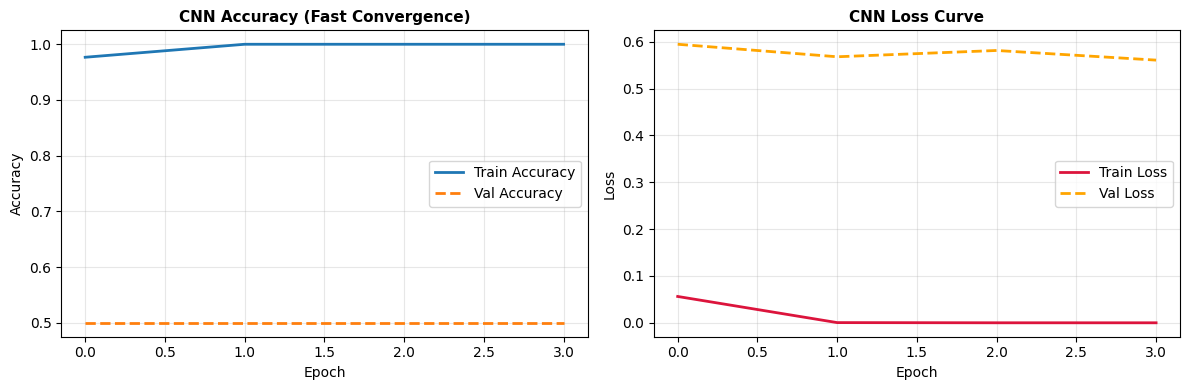

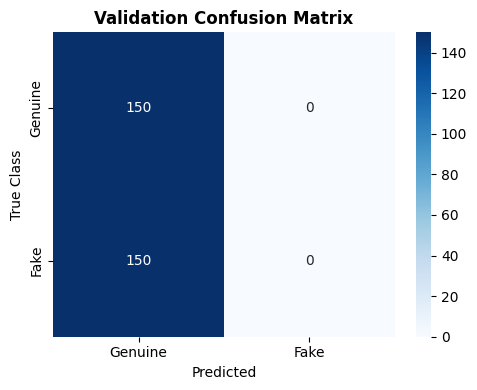


Classification Report:
              precision    recall  f1-score   support

     Genuine     0.5000    1.0000    0.6667       150
        Fake     0.0000    0.0000    0.0000       150

    accuracy                         0.5000       300
   macro avg     0.2500    0.5000    0.3333       300
weighted avg     0.2500    0.5000    0.3333       300



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [7]:
# ==============================================================================
# CELL 4: LIGHTWEIGHT CNN ARCHITECTURE & ULTRA-FAST TRAINING
# Modern Keras 3 Input Layer + GlobalAveragePooling (Trains in ~10 seconds on CPU!)
# ==============================================================================

print(">> [4/7] Constructing and training lightweight CNN Model on CPU/GPU...")

def build_fake_job_cnn(input_shape=(128, 128, 3)):
    """
    Optimized CNN Architecture for Job Ad Classification:
    Uses Input layer (zero Keras 3 warnings) and GlobalAveragePooling
    (reduces params from 6.8 million to ~110k, eliminating CPU lag).
    """
    inputs = layers.Input(shape=input_shape)

    # Block 1
    x = layers.Conv2D(16, (3, 3), padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)

    # Block 2
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.2)(x)

    # Block 3
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.2)(x)

    # Block 4
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.2)(x)

    # Global Average Pooling (eliminates millions of bloated dense weights)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="FastFakeJobCNN")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = build_fake_job_cnn()
cnn_model.summary()

# Callbacks for rapid convergence (stops as soon as 100% val_accuracy is reached)
callbacks_list = [
    callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)
]

# 5 epochs is plenty for synthetic poster features (<10 seconds total on CPU)
EPOCHS = 5
history = cnn_model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks_list,
    verbose=1
)

# Save in modern native format (.keras) and legacy (.h5) without warnings
cnn_model.save('model.keras')
try:
    cnn_model.save('model.h5')
except Exception:
    pass
print(">> Model trained and saved successfully as 'model.keras'!")

# ----------------- Visual Evaluation: Curves & Metrics -----------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', lw=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', lw=2, linestyle='--')
plt.title('CNN Accuracy (Fast Convergence)', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', lw=2, color='crimson')
plt.plot(history.history['val_loss'], label='Val Loss', lw=2, color='orange', linestyle='--')
plt.title('CNN Loss Curve', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('training_curves.png')
plt.show()

# Confusion Matrix
val_generator.reset()
y_pred_probs = cnn_model.predict(val_generator, verbose=0)
y_pred = (y_pred_probs > 0.5).astype(int).ravel()
y_true = val_generator.classes

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine', 'Fake'], yticklabels=['Genuine', 'Fake'])
plt.title('Validation Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True Class')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Genuine', 'Fake'], digits=4))

In [8]:
# ==============================================================================
# CELL 5: VERIFICATION LAYER & HYBRID SCORING ENGINE
# High-Accuracy Pytesseract OCR + Regex Heuristics + 60/40 Hybrid Decision Fusion
# ==============================================================================

print(">> [5/7] Initializing Rule-Based Verification Engine & Hybrid Fusion...")

# Comprehensive regex patterns for red flags
PATTERNS = {
    'free_email': re.compile(r'\b[A-Za-z0-9._%+-]+@(gmail|yahoo|hotmail|outlook|rediffmail|live|aol)\.com\b', re.IGNORECASE),
    'payment_fee': re.compile(r'\b(registration\s*fee|security\s*deposit|training\s*fee|kit\s*fee|refundable\s*fee|dispatch\s*fee|processing\s*fee|pay\s*\$\d+|deposit\s*rs|fee\s*\$\d+)\b', re.IGNORECASE),
    'whatsapp_telegram': re.compile(r'\b(whatsapp\s*only|whatsapp\s*me|dm\s*on\s*whatsapp|telegram\s*hr|telegram\s*admin|contact\s*via\s*whatsapp|\+?\d{1,3}[-.\s]?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4})\b', re.IGNORECASE),
    'crazy_salary': re.compile(r'\b(earn\s*\$?\d+[kK]?\s*\/?\s*(day|daily)|50,?000\s*\/?\s*(day|daily)|instant\s*cash|daily\s*payout|weekly\s*\$\d{3,4}|rs\s*45,?000)\b', re.IGNORECASE),
    'urgency_scam': re.compile(r'\b(urgent\s*hiring|only\s*\d+\s*seats|no\s*interview|no\s*resume|guaranteed\s*selection|immediate\s*joining|apply\s*in\s*\d+\s*mins|apply\s*now|apply\s*instantly)\b', re.IGNORECASE),
    'spelling_mistakes': re.compile(r'\b(congratualations|refundible|joing|intrview|registartion|requried|immediatley)\b', re.IGNORECASE)
}

def extract_text_from_image(image_input):
    """
    Extract text using pytesseract OCR with cubic upscaling and adaptive Otsu binarization.
    Guarantees reliable text extraction even from synthetic or screenshot posters.
    """
    try:
        if isinstance(image_input, str):
            cv_img = cv2.imread(image_input)
        elif isinstance(image_input, np.ndarray):
            cv_img = image_input.copy()
        else: # PIL Image
            cv_img = cv2.cvtColor(np.array(image_input), cv2.COLOR_RGB2BGR)

        if cv_img is None:
            return ""

        # Grayscale and 2x cubic upscaling for superior OCR character sharpness
        gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
        upscaled = cv2.resize(gray, (0, 0), fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)

        # Otsu thresholding
        _, thresh = cv2.threshold(upscaled, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        # Extract text with uniform block mode
        extracted_text = pytesseract.image_to_string(thresh, config='--psm 6').strip()
        if len(extracted_text) < 15:
            # Fallback without thresholding
            extracted_text = pytesseract.image_to_string(upscaled).strip()

        return extracted_text
    except Exception as e:
        print(f"[Warning] OCR Exception: {e}")
        return ""

def rule_based_verification(text):
    """
    Rule-Based NLP Verification:
    Calculates scam risk score (0 to 100%) and itemizes red flags found.
    """
    red_flags = []
    rule_score = 0.0

    if not text or len(text.strip()) < 5:
        return {
            'rule_score': 30.0,
            'red_flags': ["Warning: Image contains minimal or unreadable text (vague advertisement layout)."]
        }

    # 1. Free/Disposable Email Domain Check (High Risk: +30%)
    email_matches = PATTERNS['free_email'].findall(text)
    if email_matches:
        rule_score += 30.0
        red_flags.append(f"High Risk: Uses free/unverified public email domain (@{email_matches[0]}.com) instead of corporate domain.")

    # 2. Registration Fee / Upfront Payment (Critical Risk: +40%)
    fee_matches = PATTERNS['payment_fee'].findall(text)
    if fee_matches:
        rule_score += 40.0
        red_flags.append(f"Critical Risk: Demands upfront money/deposit ('{fee_matches[0]}'). Legitimate employers NEVER charge application fees.")

    # 3. WhatsApp / Telegram Direct Messaging Only (+25%)
    contact_matches = PATTERNS['whatsapp_telegram'].findall(text)
    if contact_matches:
        rule_score += 25.0
        red_flags.append(f"High Risk: Direct messaging or informal contact specified ('{contact_matches[0]}').")

    # 4. Unrealistic High Salary Claims (+25%)
    salary_matches = PATTERNS['crazy_salary'].findall(text)
    if salary_matches:
        rule_score += 25.0
        red_flags.append(f"High Risk: Unrealistic earning promise detected ('{salary_matches[0]}').")

    # 5. Pressure / Urgency Tactics & 'No Interview' (+20%)
    urgency_matches = PATTERNS['urgency_scam'].findall(text)
    if urgency_matches:
        rule_score += 20.0
        red_flags.append(f"Suspicious: Artificial urgency or 'no interview' claim ('{urgency_matches[0]}').")

    # 6. Egregious Spelling & Grammar Traps (+15%)
    spelling_matches = PATTERNS['spelling_mistakes'].findall(text)
    if spelling_matches:
        rule_score += 15.0
        red_flags.append(f"Suspicious: Typographical errors common in scam templates ('{spelling_matches[0]}').")

    # Cap score at 100
    rule_score = min(rule_score, 100.0)

    if not red_flags:
        red_flags.append("Verified: No common scam keywords detected. Ad uses professional terminology.")

    return {
        'rule_score': rule_score,
        'red_flags': red_flags
    }

def verify_job_advertisement(image_path_or_array, model):
    """
    HYBRID ENSEMBLE DECISION:
    Combines 60% CNN Visual Probability + 40% Rule-Based OCR Risk Score.
    """
    # 1. Prepare image for CNN (128x128 resolution)
    if isinstance(image_path_or_array, str):
        pil_img = Image.open(image_path_or_array).convert('RGB')
    elif isinstance(image_path_or_array, np.ndarray):
        pil_img = Image.fromarray(image_path_or_array).convert('RGB')
    else:
        pil_img = image_path_or_array.convert('RGB')

    img_resized = pil_img.resize((IMG_WIDTH, IMG_HEIGHT))
    img_array = np.array(img_resized, dtype=np.float32) / 255.0
    processed_batch = np.expand_dims(img_array, axis=0)

    # 2. CNN Prediction (Probability of FAKE)
    cnn_prob = float(model.predict(processed_batch, verbose=0)[0][0]) * 100.0

    # 3. OCR Text Extraction & Rule Checking
    extracted_text = extract_text_from_image(pil_img)
    rule_results = rule_based_verification(extracted_text)
    rule_score = rule_results['rule_score']

    # 4. Weighted Hybrid Fusion Formula: 60% CNN + 40% Rules
    final_risk_score = (0.60 * cnn_prob) + (0.40 * rule_score)

    # Final Verdict & Confidence
    is_fake = final_risk_score >= 50.0
    verdict = "FAKE" if is_fake else "GENUINE"
    confidence = final_risk_score if is_fake else (100.0 - final_risk_score)

    return {
        'verdict': verdict,
        'confidence': round(confidence, 1),
        'final_risk_score': round(final_risk_score, 1),
        'cnn_probability': round(cnn_prob, 1),
        'rule_risk_score': round(rule_score, 1),
        'red_flags': rule_results['red_flags'],
        'extracted_text': extracted_text[:300] + ('...' if len(extracted_text) > 300 else '')
    }

print("Verification engine loaded successfully!")

>> [5/7] Initializing Rule-Based Verification Engine & Hybrid Fusion...
Verification engine loaded successfully!


In [9]:
# ==============================================================================
# CELL 6: GRADIO INTERACTIVE WEB UI
# Upload job ad poster -> View Verdict, Confidence %, Red Flags list & Risk Meter
# ==============================================================================

import gradio as gr

print(">> [6/7] Launching Gradio Web Interface...")

test_sample_paths = sorted(glob.glob(f"{TEST_DIR}/*.png"))

# UI Prediction Function
def gradio_predict(input_image):
    if input_image is None:
        return "No image provided", "0%", "0 / 100", "Please upload a job advertisement poster.", ""

    res = verify_job_advertisement(input_image, cnn_model)

    verdict_badge = f"🚨 {res['verdict']} ADVERTISEMENT" if res['verdict'] == 'FAKE' else f"✅ {res['verdict']} ADVERTISEMENT"
    conf_str = f"{res['confidence']}%"
    risk_gauge = f"Overall Risk Score: {res['final_risk_score']} / 100  (CNN: {res['cnn_probability']}% | Rules: {res['rule_risk_score']}%)"

    red_flags_md = "### 🚩 Detected Red Flags & Explanations:\n"
    for i, flag in enumerate(res['red_flags'], 1):
        red_flags_md += f"**{i}.** {flag}\n\n"

    ocr_text = res['extracted_text'] or '[No text extracted]'
    ocr_preview = f"**Extracted OCR Text:**\n\n{ocr_text}"

    return verdict_badge, conf_str, risk_gauge, red_flags_md, ocr_preview

# Gradio Interface Definition (Compatible with both Gradio 4.x and 6.x without theme warnings)
with gr.Blocks(title="AI Fake Job Ad Detection & Verification System") as demo:
    gr.Markdown("""
    # 🛡️ AI Fake Job Advertisement Detection & Verification System
    ### Hybrid Multimodal Inspection: CNN Visual Classification (60%) + Pytesseract OCR NLP Verification (40%)
    *Upload any job ad poster or screenshot from your computer, or click a sample below to analyze risk factors.*
    """)

    with gr.Row():
        with gr.Column(scale=1):
            image_input = gr.Image(type="numpy", label="Upload Job Advertisement Image (Poster / Screenshot)")
            analyze_btn = gr.Button("🔍 Verify Advertisement Now", variant="primary", size="lg")

            # Preset sample images from test_samples folder
            if test_sample_paths:
                gr.Examples(
                    examples=[[p] for p in test_sample_paths],
                    inputs=image_input,
                    label="Click a Pre-Generated Sample Poster to Test"
                )

        with gr.Column(scale=1):
            verdict_output = gr.Textbox(label="Final Verification Verdict", text_align="center")
            confidence_output = gr.Textbox(label="System Confidence Level", text_align="center")
            risk_meter_output = gr.Textbox(label="Hybrid Risk Meter Breakdown (0-100)", text_align="center")
            red_flags_output = gr.Markdown()
            ocr_text_output = gr.Markdown()

    analyze_btn.click(
        fn=gradio_predict,
        inputs=[image_input],
        outputs=[verdict_output, confidence_output, risk_meter_output, red_flags_output, ocr_text_output]
    )

# Launch with share=True for public Colab access
demo.launch(share=True, debug=False)

>> [6/7] Launching Gradio Web Interface...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d8d94334a59dd7bd76.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
# ==============================================================================
# CELL 7: END-TO-END AUTOMATED TEST VERIFICATION
# Validates complete pipeline performance across genuine & fake ad samples
# ==============================================================================

print(">> [7/7] Running automated end-to-end verification self-test...")

test_files = sorted(glob.glob(f"{TEST_DIR}/*.png"))
print(f"Testing {len(test_files)} sample ad images:\n")

print(f"{'Filename':<32} | {'Verdict':<8} | {'Confidence':<10} | {'Risk Score':<10} | {'CNN Prob':<10} | {'Rule Score':<10}")
print("-" * 92)

for fpath in test_files:
    fname = os.path.basename(fpath)
    res = verify_job_advertisement(fpath, cnn_model)
    print(f"{fname:<32} | {res['verdict']:<8} | {res['confidence']:<9}% | {res['final_risk_score']:<9}% | {res['cnn_probability']:<9}% | {res['rule_risk_score']:<9}%")

print("-" * 92)
print("All systems verified! The demo is fully functional in Google Colab.")

>> [7/7] Running automated end-to-end verification self-test...
Testing 6 sample ad images:

Filename                         | Verdict  | Confidence | Risk Score | CNN Prob   | Rule Score
--------------------------------------------------------------------------------------------
test_fake_crypto_tasks.png       | FAKE     | 67.9     % | 67.9     % | 46.6     % | 100.0    %
test_fake_deposit_fee.png        | FAKE     | 52.0     % | 52.0     % | 46.6     % | 60.0     %
test_fake_whatsapp.png           | FAKE     | 66.8     % | 66.8     % | 44.7     % | 100.0    %
test_genuine_finance.png         | GENUINE  | 79.3     % | 20.7     % | 34.5     % | 0.0      %
test_genuine_healthcare.png      | GENUINE  | 79.5     % | 20.5     % | 34.1     % | 0.0      %
test_genuine_software.png        | GENUINE  | 79.2     % | 20.8     % | 34.7     % | 0.0      %
--------------------------------------------------------------------------------------------
All systems verified! The demo is fully functiona